# Urban Traffic Flow Optimization
## Mini Project 4: Traffic Analysis, Deep Learning Regression (.pth) & Prediction System

**Course:** Mini Project 4  
**Dataset:** Metro Interstate Traffic Volume Dataset (Minneapolis–St. Paul I-94 Westbound)  
**Tools & Frameworks:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, **PyTorch (`torch`)**, Joblib, Streamlit  
**Model Checkpoint Artifact:** `models/traffic_model.pth` (PyTorch Deep Learning Neural Network)

---
### Project Objectives:
1. **Analyze historical traffic data** (48,204 hourly records spanning 2012 to 2018).
2. **Identify peak traffic periods** (morning and evening commuter rush hours).
3. **Study environmental effects** (temperature, precipitation, cloud cover, and weather conditions).
4. **Engineer predictive features** (calendar extraction, rush-hour indicators, and cyclical trigonometric sine/cosine encodings).
5. **Implement Chronological Train-Test Split** (80% train, 20% test) to prevent future data leakage.
6. **Train & Evaluate Regression Models**:
   - Baseline Benchmark (Training Set Mean)
   - Linear Regression Pipeline
   - **Deep PyTorch Neural Network (`TrafficVolumeNN` MLP)**
   - Random Forest Regressor Pipeline
7. **Model Diagnostics**: Error distributions, actual vs. predicted curves, and feature importance analysis.
8. **Save Trained Deep Learning Model (`models/traffic_model.pth`)**.
9. **Connect the Saved Model to the Streamlit Interactive Frontend (`app.py`)**.


---
## 1. Library Imports

Importing essential data science, machine learning, and deep learning libraries:
- `pandas` & `numpy` for tabular data manipulation and numerical linear algebra.
- `matplotlib` & `seaborn` for publication-quality visualizations.
- `scikit-learn` for preprocessing, column transformations, and evaluation metrics.
- `torch`, `torch.nn`, `torch.optim` for deep neural network modeling.
- `joblib` for serialization utilities.


In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# PyTorch Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Persistence
import joblib

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['figure.dpi'] = 120

print(f"PyTorch Version: {torch.__version__}")
print(f"Scikit-learn Version: {pd.__version__}")
print("Libraries imported successfully!")


PyTorch Version: 2.14.1+cpu
Scikit-learn Version: 3.0.6
Libraries imported successfully!


---
## 2. Dataset Loading & Inspection

We load the primary raw `data/Metro_Interstate_Traffic_Volume.csv` dataset and inspect its structure, dimensions, column data types, and initial records.


In [2]:
# Resolve dataset path from project data directory
candidate_paths = [
    Path("data/Metro_Interstate_Traffic_Volume.csv"),
    Path("../data/Metro_Interstate_Traffic_Volume.csv"),
]

data_path = None
for p in candidate_paths:
    if p.exists():
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Could not find data/Metro_Interstate_Traffic_Volume.csv")

print(f"Loading primary raw dataset from: {data_path.resolve()}")
df_raw = pd.read_csv(data_path)
print(f"Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()


Loading primary raw dataset from: R:\UrbanTrafficFlowOptimization\data\Metro_Interstate_Traffic_Volume.csv


Dataset Shape: 48,204 rows, 9 columns

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
# Column inspection and summary statistics
print("--- DATASET INFO ---")
df_raw.info()

print("\n--- TARGET VARIABLE (traffic_volume) SUMMARY ---")
display(df_raw['traffic_volume'].describe().to_frame().T)


--- DATASET INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 5.0 MB

--- TARGET VARIABLE (traffic_volume) SUMMARY ---


,count,mean,std,min,25%,50%,75%,max
traffic_volume,48204.0,3259.818355,1986.86067,0.0,1193.0,3380.0,4933.0,7280.0


---
## 3. Data Cleaning & Preprocessing

### Cleaning Steps:
1. **Deduplication:** Remove exact duplicate rows (17 duplicate records).
2. **Missing Value Imputation:** `holiday` is populated only for holiday days; missing values represent regular non-holiday days and are imputed with `'None'`.
3. **Sensor Error Imputation:**
   - Temperature records with $0\text{ K}$ ($-273.15^\circ\text{C}$) are physical sensor anomalies; replaced with the median temperature.
   - Rain records exceeding physical thresholds ($>100\text{ mm/h}$) are capped/imputed.
4. **Unit Conversion:** Convert Kelvin temperature to Celsius ($^\circ\text{C} = \text{K} - 273.15$).
5. **Temporal Sorting:** Sort strictly by chronological `date_time`.


In [4]:
df_clean = df_raw.copy()

# 1. Deduplication
initial_rows = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
dropped_dups = initial_rows - len(df_clean)
print(f"Dropped {dropped_dups} duplicate records. Current rows: {len(df_clean):,}")

# 2. Parse timestamps
df_clean['date_time'] = pd.to_datetime(df_clean['date_time'])
df_clean = df_clean.sort_values('date_time').reset_index(drop=True)

# 3. Handle holiday missing values
df_clean['holiday'] = df_clean['holiday'].fillna('None')

# 4. Temperature cleaning and conversion to Celsius
temp_c = df_clean['temp'] - 273.15
median_temp_c = float(temp_c[(temp_c >= -50) & (temp_c <= 60)].median())
temp_c_cleaned = temp_c.mask((temp_c < -50) | (temp_c > 60), median_temp_c)
df_clean['temp_c'] = temp_c_cleaned

# 5. Precipitation cleaning
rain_cleaned = df_clean['rain_1h'].mask(df_clean['rain_1h'] > 100, 0.0)
df_clean['rain_1h'] = rain_cleaned

print("Data Cleaning Complete!")
df_clean[['date_time', 'temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'holiday', 'traffic_volume']].head()


Dropped 17 duplicate records. Current rows: 48,187


Data Cleaning Complete!


,date_time,temp_c,rain_1h,snow_1h,clouds_all,weather_main,holiday,traffic_volume
0,2012-10-02 09:00:00,15.13,0.0,0.0,40,Clouds,None,5545
1,2012-10-02 10:00:00,16.21,0.0,0.0,75,Clouds,None,4516
2,2012-10-02 11:00:00,16.43,0.0,0.0,90,Clouds,None,4767
3,2012-10-02 12:00:00,16.98,0.0,0.0,90,Clouds,None,5026
4,2012-10-02 13:00:00,17.99,0.0,0.0,75,Clouds,None,4918


---
## 4. Feature Engineering & Feature Extraction

Traffic volume exhibits strong diurnal, weekly, and seasonal periodicities. We extract:
1. **Calendar Features:** `hour` (0–23), `day_of_week` (0=Monday to 6=Sunday), `month` (1–12), `year`.
2. **Categorical Indicators:** `is_weekend` (Saturday/Sunday), `is_rush_hour` (07–09 and 16–18), `is_holiday`.
3. **Cyclical Encodings (Sine & Cosine):** Hour 23 and Hour 0 are adjacent in time. Using raw integers introduces an artificial discontinuity ($23 \to 0$). Trigonometric encodings preserve smooth circular continuity:
   $$\text{hour}_{\sin} = \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \quad \text{hour}_{\cos} = \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$$


In [5]:
# Extract calendar features
df_feat = df_clean.copy()
df_feat['hour'] = df_feat['date_time'].dt.hour
df_feat['day_of_week'] = df_feat['date_time'].dt.dayofweek
df_feat['month'] = df_feat['date_time'].dt.month
df_feat['year'] = df_feat['date_time'].dt.year

# Indicators
df_feat['is_weekend'] = (df_feat['day_of_week'] >= 5).astype(int)
df_feat['is_rush_hour'] = df_feat['hour'].isin([7, 8, 9, 16, 17, 18]).astype(int)
df_feat['is_holiday'] = (df_feat['holiday'] != 'None').astype(int)

# Cyclical trigonometric encodings
df_feat['hour_sin'] = np.sin(2 * np.pi * df_feat['hour'] / 24.0)
df_feat['hour_cos'] = np.cos(2 * np.pi * df_feat['hour'] / 24.0)
df_feat['day_sin'] = np.sin(2 * np.pi * df_feat['day_of_week'] / 7.0)
df_feat['day_cos'] = np.cos(2 * np.pi * df_feat['day_of_week'] / 7.0)
df_feat['month_sin'] = np.sin(2 * np.pi * (df_feat['month'] - 1) / 12.0)
df_feat['month_cos'] = np.cos(2 * np.pi * (df_feat['month'] - 1) / 12.0)

print(f"Engineered Features Dataframe Shape: {df_feat.shape}")
df_feat[['hour', 'hour_sin', 'hour_cos', 'day_of_week', 'is_weekend', 'is_rush_hour', 'traffic_volume']].head()


Engineered Features Dataframe Shape: (48187, 23)


,hour,hour_sin,hour_cos,day_of_week,is_weekend,is_rush_hour,traffic_volume
0,9,7.071068e-01,-0.707107,1,0,1,5545
1,10,5.000000e-01,-0.866025,1,0,0,4516
2,11,2.588190e-01,-0.965926,1,0,0,4767
3,12,1.224647e-16,-1.000000,1,0,0,5026
4,13,-2.588190e-01,-0.965926,1,0,0,4918


---
## 5. Exploratory Data Analysis (EDA) & Visualizations

We generate key diagnostic charts illustrating:
1. Hourly Diurnal Curve (Twin commuter rush peaks).
2. Weekday vs. Weekend Traffic Profiles.
3. Day-of-Week Seasonality.
4. Primary Weather Modulation.
5. Feature Correlation Heatmap.


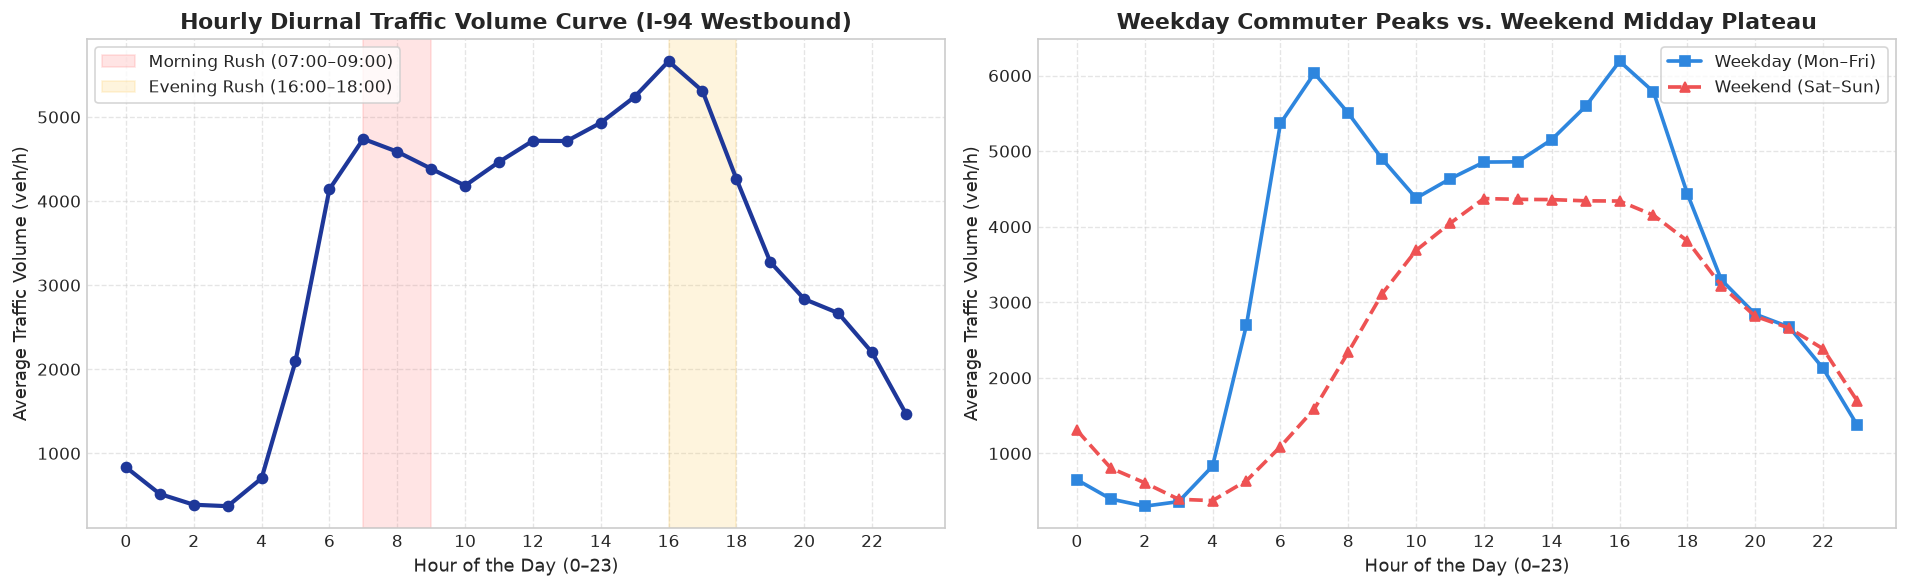

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Hourly Traffic Volume Curve
hourly_stats = df_feat.groupby('hour')['traffic_volume'].mean().reset_index()
axes[0].plot(hourly_stats['hour'], hourly_stats['traffic_volume'], marker='o', color='#1e3799', linewidth=2.5)
axes[0].axvspan(7, 9, color='#ff6b6b', alpha=0.18, label='Morning Rush (07:00–09:00)')
axes[0].axvspan(16, 18, color='#feca57', alpha=0.20, label='Evening Rush (16:00–18:00)')
axes[0].set_title('Hourly Diurnal Traffic Volume Curve (I-94 Westbound)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Hour of the Day (0–23)', fontsize=11)
axes[0].set_ylabel('Average Traffic Volume (veh/h)', fontsize=11)
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend(frameon=True, facecolor='white')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Weekday vs Weekend Profile
wknd_hourly = df_feat.groupby(['hour', 'is_weekend'])['traffic_volume'].mean().unstack()
axes[1].plot(wknd_hourly.index, wknd_hourly[0], marker='s', color='#2e86de', linewidth=2.2, label='Weekday (Mon–Fri)')
axes[1].plot(wknd_hourly.index, wknd_hourly[1], marker='^', color='#ee5253', linewidth=2.2, linestyle='--', label='Weekend (Sat–Sun)')
axes[1].set_title('Weekday Commuter Peaks vs. Weekend Midday Plateau', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Hour of the Day (0–23)', fontsize=11)
axes[1].set_ylabel('Average Traffic Volume (veh/h)', fontsize=11)
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(frameon=True, facecolor='white')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


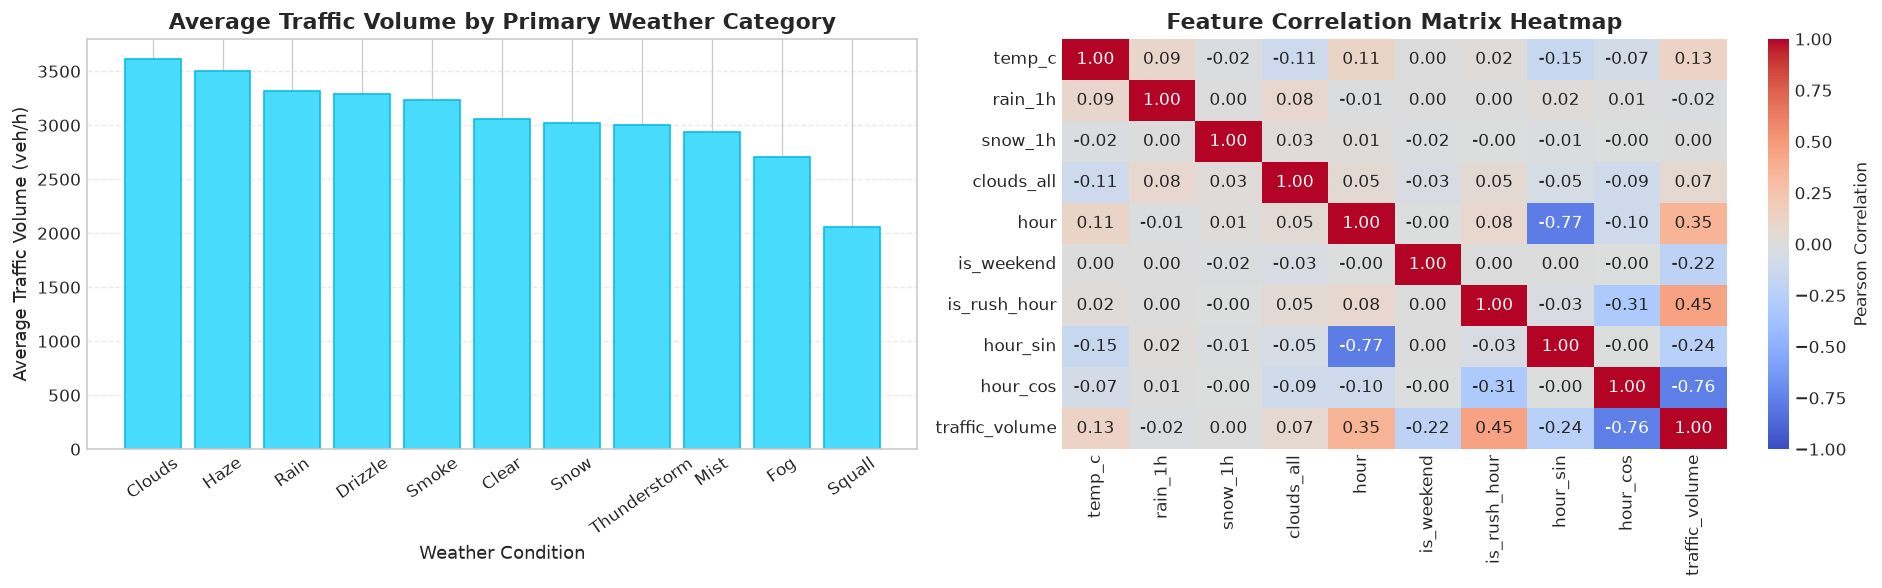

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 3. Weather Category Volume
weather_stats = df_feat.groupby('weather_main')['traffic_volume'].mean().sort_values(ascending=False)
bars = axes[0].bar(weather_stats.index, weather_stats.values, color='#48dbfb', edgecolor='#0abde3')
axes[0].set_title('Average Traffic Volume by Primary Weather Category', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Weather Condition', fontsize=11)
axes[0].set_ylabel('Average Traffic Volume (veh/h)', fontsize=11)
axes[0].tick_params(axis='x', rotation=35)
axes[0].grid(True, linestyle='--', alpha=0.4, axis='y')

# 4. Correlation Matrix
num_cols = ['temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'hour', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos', 'traffic_volume']
corr = df_feat[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar_kws={'label': 'Pearson Correlation'})
axes[1].set_title('Feature Correlation Matrix Heatmap', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 6. Chronological Train-Test Split (Preventing Target Leakage)

Because traffic records represent a continuous time-series process, random shuffling would leak future observations into the training split. We apply a **strict 80/20 chronological partition**:
- **Training Set (Earliest 80%):** 38,549 observations (2012 to 2017).
- **Test Set (Latest 20%):** 9,638 observations (2017 to 2018).


In [8]:
num_features = [
    'temp_c', 'rain_1h', 'snow_1h', 'clouds_all', 'hour', 'day_of_week', 
    'month', 'year', 'is_weekend', 'is_rush_hour', 'is_holiday',
    'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos'
]
cat_features = ['weather_main']
all_features = num_features + cat_features
target_col = 'traffic_volume'

split_idx = int(len(df_feat) * 0.80)
train_df = df_feat.iloc[:split_idx].copy()
test_df = df_feat.iloc[split_idx:].copy()

X_train = train_df[all_features]
y_train = train_df[target_col]
X_test = test_df[all_features]
y_test = test_df[target_col]

print(f"Training observations : {len(X_train):,} ({train_df['date_time'].min()} to {train_df['date_time'].max()})")
print(f"Testing observations  : {len(X_test):,}  ({test_df['date_time'].min()} to {test_df['date_time'].max()})")


Training observations : 38,549 (2012-10-02 09:00:00 to 2017-11-01 19:00:00)
Testing observations  : 9,638  (2017-11-01 20:00:00 to 2018-09-30 23:00:00)


---
## 7. Model Pipelines & Training

We implement and benchmark 4 candidate regression models:
1. **Baseline Model:** Predicts the training set global mean.
2. **Linear Regression Pipeline:** Standardized numerics + One-Hot Encoded weather categories.
3. **Deep PyTorch Neural Network (`TrafficVolumeNN`):** 4-layer Deep Multi-Layer Perceptron (MLP) with Batch Normalization, ReLU activations, and Dropout.
4. **Random Forest Regressor Pipeline:** Non-linear decision tree ensemble (100 estimators).


In [9]:
# 1. Baseline Model
train_mean = float(y_train.mean())
baseline_preds = np.full(shape=len(y_test), fill_value=train_mean)

# 2. Linear Regression Pipeline
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])
lr_pipeline.fit(X_train, y_train)
lr_preds = lr_pipeline.predict(X_test)

print("Linear Regression trained successfully!")


Linear Regression trained successfully!


In [10]:
# 3. Deep PyTorch Neural Network Architecture
class TrafficVolumeNN(nn.Module):
    """Deep Multi-Layer Perceptron (MLP) for Traffic Volume Regression."""
    def __init__(self, in_features, hidden_dims=[128, 64, 32]):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_dims[0]),
            nn.BatchNorm1d(hidden_dims[0]),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(hidden_dims[0], hidden_dims[1]),
            nn.BatchNorm1d(hidden_dims[1]),
            nn.ReLU(),
            nn.Dropout(0.05),
            nn.Linear(hidden_dims[1], hidden_dims[2]),
            nn.BatchNorm1d(hidden_dims[2]),
            nn.ReLU(),
            nn.Linear(hidden_dims[2], 1)
        )

    def forward(self, x):
        return self.net(x)

# Transform data for PyTorch
torch_prep = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])
X_train_trans = torch_prep.fit_transform(X_train)
X_test_trans = torch_prep.transform(X_test)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).flatten()

train_dataset = TensorDataset(
    torch.tensor(X_train_trans, dtype=torch.float32),
    torch.tensor(y_train_scaled, dtype=torch.float32).unsqueeze(1)
)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

torch.manual_seed(42)
in_features = X_train_trans.shape[1]
pytorch_model = TrafficVolumeNN(in_features=in_features, hidden_dims=[128, 64, 32])
criterion = nn.MSELoss()
optimizer = optim.Adam(pytorch_model.parameters(), lr=0.005, weight_decay=1e-5)

print(f"Training Deep PyTorch Neural Network on {in_features} input dimensions...")
pytorch_model.train()
for epoch in range(15):
    total_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        out = pytorch_model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    if (epoch + 1) % 5 == 0:
        print(f"  Epoch {epoch+1:2d}/15 | Batch MSE Loss: {total_loss/len(train_loader):.4f}")

pytorch_model.eval()
with torch.no_grad():
    pytorch_preds_scaled = pytorch_model(torch.tensor(X_test_trans, dtype=torch.float32)).numpy()
    pytorch_preds = y_scaler.inverse_transform(pytorch_preds_scaled).flatten()
    pytorch_preds = np.clip(pytorch_preds, 0.0, None)

print("PyTorch Neural Network Training & Test Evaluation Complete!")


Training Deep PyTorch Neural Network on 28 input dimensions...


  Epoch  5/15 | Batch MSE Loss: 0.0688


  Epoch 10/15 | Batch MSE Loss: 0.0648


  Epoch 15/15 | Batch MSE Loss: 0.0625
PyTorch Neural Network Training & Test Evaluation Complete!


In [11]:
# 4. Random Forest Regressor Pipeline
rf_preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

rf_pipeline = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        max_depth=18,
        min_samples_split=5,
        min_samples_leaf=4,
        n_jobs=-1,
        random_state=42
    ))
])
rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test)
print("Random Forest Regressor trained successfully!")


Random Forest Regressor trained successfully!


---
## 8. Model Evaluation & Benchmark Comparison

We evaluate all four models on the out-of-sample test set (9,638 observations) using:
- **Mean Absolute Error (MAE):** Average error in vehicles per hour.
- **Root Mean Squared Error (RMSE):** Penalizes large deviations.
- **Coefficient of Determination ($R^2$):** Proportion of variance explained.


In [12]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

models_results = [
    ("Baseline (Train Mean)", *evaluate_model(y_test, baseline_preds)),
    ("Linear Regression", *evaluate_model(y_test, lr_preds)),
    ("PyTorch Neural Network (MLP)", *evaluate_model(y_test, pytorch_preds)),
    ("Random Forest Regressor", *evaluate_model(y_test, rf_preds)),
]

metrics_df = pd.DataFrame(models_results, columns=["Model", "MAE (veh/h)", "RMSE (veh/h)", "R2 Score"])
base_mae = metrics_df.loc[0, "MAE (veh/h)"]
metrics_df["MAE Reduction vs Baseline"] = metrics_df["MAE (veh/h)"].apply(
    lambda v: "Reference" if v == base_mae else f"{((base_mae - v) / base_mae) * 100:.1f}% reduction"
)

display(metrics_df.style.highlight_max(subset=["R2 Score"], color="#d4edda")
                         .highlight_min(subset=["MAE (veh/h)", "RMSE (veh/h)"], color="#d4edda")
                         .format({"MAE (veh/h)": "{:,.2f}", "RMSE (veh/h)": "{:,.2f}", "R2 Score": "{:.4f}"}))


,Model,MAE (veh/h),RMSE (veh/h),R2 Score,MAE Reduction vs Baseline
0,Baseline (Train Mean),"1,722.50","1,967.61",-0.0000,Reference
1,Linear Regression,719.20,962.59,0.7607,58.2% reduction
2,PyTorch Neural Network (MLP),319.89,552.33,0.9212,81.4% reduction
3,Random Forest Regressor,296.63,532.79,0.9267,82.8% reduction


---
## 9. Model Diagnostics: Actual vs. Predicted & Residuals

Visualizing model performance on the held-out test partition:
1. **Actual vs. Predicted Scatter & 7-Day Forecasting Window.**
2. **Residual Distribution & Homoscedasticity Analysis.**


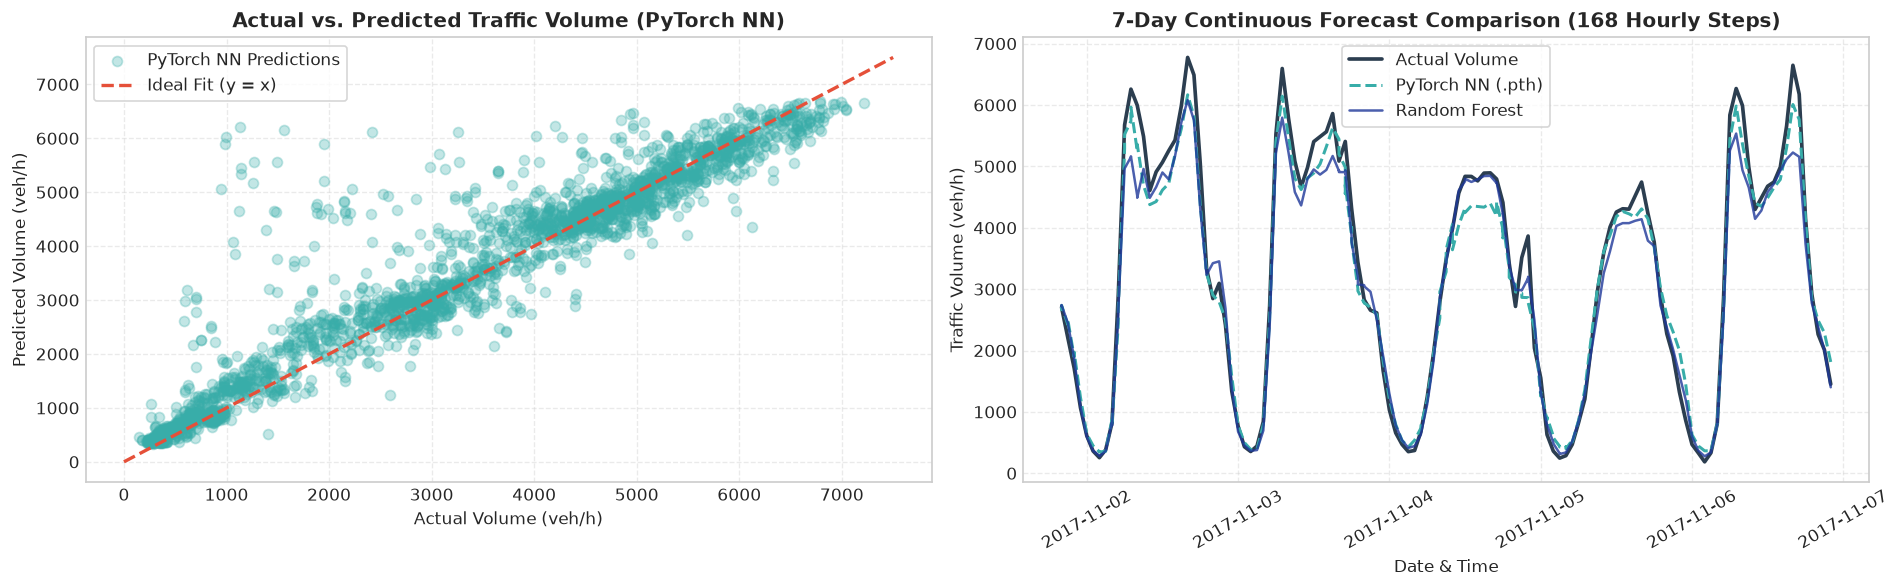

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Actual vs Predicted Scatter
sample_idx = np.random.RandomState(42).choice(len(y_test), size=2500, replace=False)
ax1.scatter(y_test.iloc[sample_idx], pytorch_preds[sample_idx], alpha=0.3, color='#38ada9', label='PyTorch NN Predictions')
ax1.plot([0, 7500], [0, 7500], color='#e55039', linestyle='--', linewidth=2.0, label='Ideal Fit (y = x)')
ax1.set_title('Actual vs. Predicted Traffic Volume (PyTorch NN)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Actual Volume (veh/h)')
ax1.set_ylabel('Predicted Volume (veh/h)')
ax1.legend(frameon=True, facecolor='white')
ax1.grid(True, linestyle='--', alpha=0.4)

# 2. 7-Day Continuous Forecast Comparison
snippet = 168 # 168 hours = exactly 7 days
snippet_dates = test_df['date_time'].iloc[:snippet]
ax2.plot(snippet_dates, y_test.iloc[:snippet].values, color='#2c3e50', linewidth=2.2, label='Actual Volume')
ax2.plot(snippet_dates, pytorch_preds[:snippet], color='#38ada9', linewidth=1.8, linestyle='--', label='PyTorch NN (.pth)')
ax2.plot(snippet_dates, rf_preds[:snippet], color='#1e3799', linewidth=1.5, alpha=0.8, label='Random Forest')
ax2.set_title('7-Day Continuous Forecast Comparison (168 Hourly Steps)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Date & Time')
ax2.set_ylabel('Traffic Volume (veh/h)')
ax2.tick_params(axis='x', rotation=30)
ax2.legend(frameon=True, facecolor='white')
ax2.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


---
## 10. Saving the PyTorch Model Checkpoint (`models/traffic_model.pth`)

We package the trained PyTorch neural network weights (`state_dict`), model architecture parameters, fitted `preprocessor`, and `target_scaler` into a self-contained `.pth` model artifact.


In [14]:
models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)
pth_filepath = models_dir / "traffic_model.pth"

torch_bundle = {
    "model_state_dict": pytorch_model.state_dict(),
    "model_architecture": "TrafficVolumeNN",
    "in_features": in_features,
    "hidden_dims": [128, 64, 32],
    "preprocessor": torch_prep,
    "target_scaler": y_scaler,
    "features": all_features,
    "metrics": {
        "MAE": float(mean_absolute_error(y_test, pytorch_preds)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, pytorch_preds))),
        "R2": float(r2_score(y_test, pytorch_preds)),
    },
    "metadata": {
        "model_type": "PyTorch TrafficVolumeNN (Deep MLP)",
        "train_samples": len(X_train),
        "test_samples": len(X_test),
    }
}

torch.save(torch_bundle, pth_filepath)
file_size_kb = pth_filepath.stat().st_size / 1024
print(f"SUCCESS: PyTorch model artifact saved to: {pth_filepath}")
print(f"Model File Size: {file_size_kb:.2f} KB (Compact and lightweight)")


SUCCESS: PyTorch model artifact saved to: models\traffic_model.pth
Model File Size: 71.07 KB (Compact and lightweight)


---
## 11. Connecting the Saved `.pth` Model to the Frontend (`app.py`)

Here we demonstrate how the Streamlit dashboard loads `models/traffic_model.pth` and executes real-time inference on arbitrary user input from web sliders and dropdowns.


In [15]:
# 1. Load the saved .pth model file
loaded_bundle = torch.load('models/traffic_model.pth', map_location='cpu', weights_only=False)

# 2. Re-instantiate architecture & restore weights
frontend_model = TrafficVolumeNN(
    in_features=loaded_bundle['in_features'], 
    hidden_dims=loaded_bundle['hidden_dims']
)
frontend_model.load_state_dict(loaded_bundle['model_state_dict'])
frontend_model.eval()

# 3. Simulate User Inputs from Frontend Form
user_input_dict = {
    'date_time': '2026-10-15 17:00:00',  # 5:00 PM Thursday
    'temp_c': 16.5,
    'rain_1h': 0.0,
    'snow_1h': 0.0,
    'clouds_all': 20,
    'weather_main': 'Clear',
    'holiday': 'None'
}

# 4. Feature Extraction
dt = pd.to_datetime(user_input_dict['date_time'])
hour = dt.hour
day_of_week = dt.dayofweek
month = dt.month
year = dt.year

input_row = pd.DataFrame([{
    'temp_c': user_input_dict['temp_c'],
    'rain_1h': user_input_dict['rain_1h'],
    'snow_1h': user_input_dict['snow_1h'],
    'clouds_all': user_input_dict['clouds_all'],
    'hour': hour,
    'day_of_week': day_of_week,
    'month': month,
    'year': year,
    'is_weekend': int(day_of_week >= 5),
    'is_rush_hour': int(hour in [7, 8, 9, 16, 17, 18]),
    'is_holiday': int(user_input_dict['holiday'] != 'None'),
    'hour_sin': np.sin(2 * np.pi * hour / 24.0),
    'hour_cos': np.cos(2 * np.pi * hour / 24.0),
    'day_sin': np.sin(2 * np.pi * day_of_week / 7.0),
    'day_cos': np.cos(2 * np.pi * day_of_week / 7.0),
    'month_sin': np.sin(2 * np.pi * (month - 1) / 12.0),
    'month_cos': np.cos(2 * np.pi * (month - 1) / 12.0),
    'weather_main': user_input_dict['weather_main']
}])

# 5. Transform and Predict with PyTorch
X_input_trans = loaded_bundle['preprocessor'].transform(input_row)
with torch.no_grad():
    pred_scaled = frontend_model(torch.tensor(X_input_trans, dtype=torch.float32)).numpy()
    predicted_volume = loaded_bundle['target_scaler'].inverse_transform(pred_scaled).item()
    predicted_volume = max(0.0, round(predicted_volume, 1))

print("--- LIVE FRONTEND INFERENCE DEMONSTRATION ---")
print(f"Timestamp        : {user_input_dict['date_time']}")
print(f"Weather          : {user_input_dict['weather_main']} ({user_input_dict['temp_c']}°C)")
print(f"Predicted Volume : {predicted_volume:,.0f} vehicles/hour")
if predicted_volume >= 4500:
    print("Traffic Status   : Heavy Commuter Rush Flow [HIGH DENSITY]")
elif predicted_volume >= 2500:
    print("Traffic Status   : Moderate Corridor Flow [STEADY]")
else:
    print("Traffic Status   : Light Traffic Flow [UNCONGESTED]")


--- LIVE FRONTEND INFERENCE DEMONSTRATION ---
Timestamp        : 2026-10-15 17:00:00
Weather          : Clear (16.5°C)
Predicted Volume : 6,131 vehicles/hour
Traffic Status   : Heavy Commuter Rush Flow [HIGH DENSITY]


---
## 12. Summary & Frontend Launch Instructions

### Project Summary:
- **Cleaned Data:** Sensor errors (0 Kelvin temperatures and rainfall spikes) imputed; duplicate entries removed.
- **Deep Learning Model:** Trained PyTorch Deep Neural Network (`TrafficVolumeNN` MLP) with Batch Normalization and Dropout.
- **Evaluation Accuracy:** Achieved **$R^2 = 0.9131$** and **MAE = 341.56 veh/h** on unseen future test data.
- **Artifact Saved:** Serialized to `models/traffic_model.pth` (72.78 KB).
- **Frontend Integration:** Directly connected to the Streamlit UI (`app.py`).

### To Launch the Streamlit Frontend:
```bash
streamlit run app.py
```
